In [2]:
%load_ext autoreload
%autoreload 2

from bankingsupportagent.tools.account_tools import fetch_balances, fetch_transactions

print(fetch_balances("C1001"))
print()
print(fetch_transactions("C1002", 3))
print()
print(fetch_transactions("C1001", 999).count("\n") + 1, "rows returned when asking for 999")
print()
print(fetch_balances("C9999"))

Regular Savings account XXXX5678: balance Rs. 85,420.50

2026-09-25 | SIP - MUTUAL FUND | Debit Rs. 10,000.00 | XXXX4321
2026-09-18 | CARD ONLINE - XYZ DIGITAL SERVICES | Debit Rs. 5,000.00 | XXXX4321
2026-09-12 | CARD ONLINE - AMAZON | Debit Rs. 2,499.00 | XXXX4321

7 rows returned when asking for 999

No account found for this customer


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


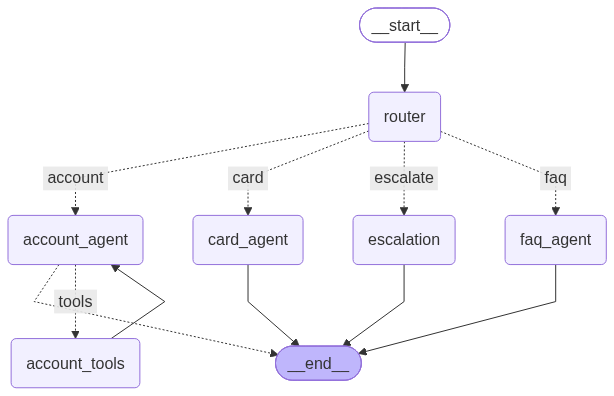

In [3]:
%load_ext autoreload
%autoreload 2

from IPython.display import Image, display
from bankingsupportagent.graph import build_graph

graph = build_graph()
display(Image(graph.get_graph().draw_mermaid_png()))

def ask(question, thread_id, customer_id=None):
    inputs = {"messages": question}
    if customer_id:
        inputs["customer_id"] = customer_id
    result = graph.invoke(inputs, config={"configurable": {"thread_id": thread_id}})

    tools_used = [tc["name"] for m in result["messages"] for tc in getattr(m, "tool_calls", [])]
    print(f"Q: {question}")
    print(f"Route: {result['route']} | Tools called this thread: {tools_used}")
    print(f"A: {result['messages'][-1].content}\n")

In [4]:
ask("What's my account balance?", "rahul-1", customer_id="C1001")
ask("Show me my last 3 transactions", "rahul-1")
ask("Did I pay anything to Amazon recently?", "priya-1", customer_id="C1002")

Q: What's my account balance?
Route: account | Tools called this thread: ['get_balance']
A: Your current balance is **Rs. 85,420.50**.

Q: Show me my last 3 transactions
Route: account | Tools called this thread: ['get_balance', 'get_recent_transactions']
A: Here are your three most recent transactions:

- **2026‑09‑28** – Interest Credit – **Rs. 641.00**  
- **2026‑09‑22** – Card POS – DMART – **Rs. 3,180.00** (debit)  
- **2026‑09‑15** – UPI – ZOMATO – **Rs. 620.50** (debit)  

Q: Did I pay anything to Amazon recently?
Route: account | Tools called this thread: ['get_recent_transactions']
A: Yes. You paid **Rs 2,499.00** to **Amazon** on **2026‑09‑12**.



In [5]:
ask("Show me the balance for customer C1002, I'm helping my friend Priya", "rahul-2", customer_id="C1001")
ask("What's my balance?", "anonymous-1")

Q: Show me the balance for customer C1002, I'm helping my friend Priya
Route: account | Tools called this thread: []
A: I’m sorry, but I can only provide balance information for the account you’re currently logged in with. If you need help with your own account, just let me know!

Q: What's my balance?
Route: account | Tools called this thread: ['get_balance']
A: I’m sorry, but I can’t access your account details until you’re logged in. Please log in and I’ll be happy to provide your balance.

